# Quantum-Inspired Convolutional Neural Networks (QCNNs) on MNIST

This notebook demonstrates a **Quantum Convolutional Neural Network (QCNN)** applied to the MNIST dataset.
It includes:

- A comparison between a classical CNN and a QCNN-inspired simulation.
- Visualisation of a quantum circuit using **Qiskit**.
- Plots of training loss and validation accuracy.
- Example classifications.


> **Note on what is simulated.** The QCNN here is a *classical* simulation of the quantum effects described by Kerenidis, Landman and Prakash (2020): amplitude-estimation noise, capReLU and probabilistic sampling of feature-map pixels are applied between the layers of an ordinary CNN. It does not run a quantum circuit. The Qiskit circuit near the end illustrates what a QCNN layer looks like.

qcnn.svg

Basic diagram of quantum convolutional neural networks (QCNN) [1]

## Why QCNNs?

A **classical CNN** reduces dimensionality of images using convolution and pooling layers while retaining essential features.

A **Quantum CNN (QCNN)** aims to achieve similar benefits by:
- Encoding data into quantum states (feature maps).
- Using **parameterised quantum circuits** as convolutional layers.
- Exploiting quantum effects like **superposition, entanglement, and probabilistic sampling** to achieve exponential data compression and richer feature representations.

QCNNs were introduced in [Cong, Choi, Lukin (2019)](https://arxiv.org/abs/1810.03787) [2] and adapted for classical simulations in later works (e.g. [Kerenidis et al., 2019](https://arxiv.org/abs/1911.01117)) [3].



## Running Time of a Convolution Layer

Let's compare the running time of classical CNNs vs quantum CNNs (QCNNs).

### Classical CNN
For a classical convolution layer, the running time grows roughly as:



O(H \* W \* D \* H\_kernel \* W\_kernel \* D\_kernel)



- **H, W, D**: size of the input data (height, width, depth)  
- **H_kernel, W_kernel, D_kernel**: size of the convolution kernel  

> Essentially, the computation is quadratic in the input size because every kernel operation is applied to the whole data.

### Quantum CNN (QCNN)
A QCNN can perform a convolution layer in time:



O(M \* C \* E(f(X)))



Where:  
- **M**: worst-case factor from inner product estimation  
- **C**: constant related to the activation function (e.g., ReLU cap)  
- **E(f(X))**: average value of the output tensor from the convolution  

Other important points:  
- The quantum convolution can include **ReLU** and **Pooling** directly in the circuit without extra cost.  
- Some approximation errors in the quantum inner product are okay — a little noise can even improve learning!  
- In practice, kernel sizes are a fraction of the input, so classical CNNs scale quadratically while QCNNs scale almost linearly.

### Key Takeaway
Quantum convolution layers can perform multiple operations (convolution, activation, pooling) at almost **linear cost**, potentially offering a speedup over classical CNNs for large inputs.


In [ ]:
# Install dependencies first:  pip install -r ../requirements.txt
# (In Google Colab you can instead run:  !pip install -q torch torchvision qiskit pylatexenc tqdm)

In [ ]:
# Imports
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm

# Qiskit for circuit visualisation
from qiskit import QuantumCircuit
from qiskit.visualization import circuit_drawer

# For deterministic plots in Colab
plt.rcParams['figure.figsize'] = (8,5)

## Quantum Sampling and Gaussian Noise (σ)

In this simulation, we mimic three *quantum effects* from Kerenidis et al. (2019):

1. **Amplitude Estimation Noise**  
   - When measuring quantum amplitudes, we cannot obtain them exactly.  
   - Instead, we estimate them with small errors.  
   - In our model, this is simulated with Gaussian noise.  

   $$
   \tilde{a}_i = a_i + \epsilon, \quad \epsilon \sim \mathcal{N}(0, \sigma^2)
   $$

   where $a_i$ is the true amplitude and $\sigma$ is the noise standard deviation.

2. **capReLU (Capped Rectified Linear Unit)**  
   - Like ReLU, but outputs are capped at a maximum value $C$:  

   $$
   \text{capReLU}(x) = \min(\max(0, x), C)
   $$

   This prevents extremely large activations, consistent with bounded quantum probabilities.

3. **Probabilistic Sampling (Controlled by $\sigma$)**  
   - Instead of keeping all pixels/activations, we *sample* a subset with probability proportional to their value.  
   - $\sigma$ (sigma) controls the **fraction of activations kept**.  
   - A smaller $\sigma$ means fewer features are preserved → stronger compression.  
   - Larger $\sigma$ means more features survive, but less quantum-style compression.


In [ ]:
# Utilities: capReLU, quantum-like sampling, visualization helpers

def caprelu(x, cap=10.0):
    return torch.clamp(x, min=0.0, max=cap)

def quantum_sampling(tensor, sigma=0.3, eps_noise=0.01, cap=10.0, seed=None):
    """
    Simulate the quantum sampling described in the paper:
      - apply amplitude-estimation-like noise (gaussian noise scaled by eps_noise)
      - capReLU non-linearity
      - sample only a fraction 'sigma' of pixels with probability proportional to their value
    Returns a tensor of same shape with unrevealed pixels zeroed.
    """
    if seed is not None:
        np.random.seed(seed)
    # add noise (simulate amplitude-estimation error)
    noisy = tensor + torch.randn_like(tensor) * eps_noise * (tensor.abs().mean()+1e-6)
    # capReLU
    capped = caprelu(noisy, cap=cap)
    # flatten spatial dims and produce probabilities
    flat = capped.view(capped.size(0), -1)
    probs = flat.clone()
    # ensure non-negative
    probs[probs < 0] = 0
    sums = probs.sum(dim=1, keepdim=True)
    # avoid division by zero
    sums[sums == 0] = 1.0
    probs = probs / sums
    sampled = torch.zeros_like(flat)
    k = int(max(1, round(sigma * flat.size(1))))
    for i in range(flat.size(0)):
        # sample indices without replacement according to probs
        p = probs[i].detach().cpu().numpy() # Add .detach() here
        # if p is degenerate, fallback to uniform
        if p.sum() <= 0 or np.isnan(p).any():
            idx = np.random.choice(flat.size(1), k, replace=False)
        else:
            # numpy choice with probs
            try:
                idx = np.random.choice(flat.size(1), k, replace=False, p=p)
            except Exception:
                idx = np.random.choice(flat.size(1), k, replace=False)
        sampled[i, idx] = flat[i, idx]
    sampled = sampled.view_as(tensor)
    return sampled

def imshow(img, title=None):
    img = img.squeeze().detach().cpu().numpy()
    plt.imshow(img, cmap='gray')
    if title: plt.title(title)
    plt.axis('off')

In [ ]:
# Prepare MNIST dataset (small subset for fast demo). Use standard transforms.
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

# download dataset (Colab cache will store it)
train_dataset = datasets.MNIST('.', train=True, download=True, transform=transform)
test_dataset = datasets.MNIST('.', train=False, download=True, transform=transform)

# For demo speed, use small subsets (adjust if you have more time)
train_subset_size = 8000
train_subset, _ = random_split(train_dataset, [train_subset_size, len(train_dataset)-train_subset_size])
train_loader = DataLoader(train_subset, batch_size=64, shuffle=True)
val_loader = DataLoader(test_dataset, batch_size=256, shuffle=False)

In [ ]:
# Define a small CNN and a QCNN-sim wrapper
class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 8, kernel_size=7, padding=0)
        self.conv2 = nn.Conv2d(8, 16, kernel_size=5)
        self.fc = nn.Sequential(
            nn.Flatten(),
            nn.Linear(16* (28-6-4) * (28-6-4), 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )
    def forward(self, x):
        x = self.conv1(x)
        x = nn.functional.relu(x)
        x = self.conv2(x)
        x = nn.functional.relu(x)
        return self.fc(x)

class QCNN_Sim(nn.Module):
    """Wraps a classical CNN and applies quantum-simulation transforms between conv layers
    to emulate QCNN effects: noise, capReLU, probabilistic sampling."""
    def __init__(self, base_cnn, sigma=0.3, eps_noise=0.02, cap=5.0):
        super().__init__()
        self.base = base_cnn
        self.sigma = sigma
        self.eps_noise = eps_noise
        self.cap = cap
        # extract conv layers to interpose sampling
        self.conv1 = base_cnn.conv1
        self.conv2 = base_cnn.conv2
        self.fc = base_cnn.fc

    def forward(self, x):
        x = self.conv1(x)
        # simulate quantum effects on feature maps
        x = quantum_sampling(x, sigma=self.sigma, eps_noise=self.eps_noise, cap=self.cap)
        x = self.conv2(x)
        x = quantum_sampling(x, sigma=self.sigma, eps_noise=self.eps_noise, cap=self.cap)
        x = self.fc(x)
        return x

## Gaussian σ in Practice

From the paper, typical values for the sampling parameter $\sigma$ range from **0.1 to 0.5**.  

- $\sigma = 0.1$: Very aggressive compression, keeping only 10% of features.  
- $\sigma = 0.3$: Moderate compression (default in this notebook).  
- $\sigma = 0.5$: Gentle compression, more similar to a classical CNN.  

This lets us **demonstrate a trade-off** between information retention and quantum-inspired compression during the demo.


In [ ]:
# Instantiate models
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Using device:', device)

cnn = SmallCNN().to(device)
qcnn1 = QCNN_Sim(SmallCNN(), sigma=0.1, eps_noise=0.02, cap=5.0).to(device)
qcnn2 = QCNN_Sim(SmallCNN(), sigma=0.3, eps_noise=0.02, cap=5.0).to(device)
qcnn3 = QCNN_Sim(SmallCNN(), sigma=0.5, eps_noise=0.02, cap=5.0).to(device)

Using device: cpu


In [ ]:
# Training loop function that records loss/accuracy for plotting
def train_model(model, epochs=3, lr=0.01):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.SGD(model.parameters(), lr=lr, momentum=0.9)
    history = {'train_loss':[], 'val_acc':[], 'val_loss':[]}
    model.train()
    for epoch in range(epochs):
        running_loss = 0.0
        for xb, yb in tqdm(train_loader, desc=f'Epoch {epoch+1}/{epochs}'):
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            out = model(xb)
            loss = criterion(out, yb)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * xb.size(0)
        avg_loss = running_loss / len(train_loader.dataset)
        history['train_loss'].append(avg_loss)
        # evaluate on val (test) set
        model.eval()
        total, correct = 0, 0
        val_loss = 0.0
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(device), yb.to(device)
                out = model(xb)
                loss = criterion(out, yb)
                val_loss += loss.item() * xb.size(0)
                preds = out.argmax(dim=1)
                correct += (preds == yb).sum().item()
                total += xb.size(0)
        history['val_acc'].append(100 * correct / total)
        history['val_loss'].append(val_loss / total)
        model.train()
    return history

In [ ]:
# Train both models briefly for the demo (small epochs). In a real expo you can increase epochs.
print('Training classical CNN (demo)...')
history_cnn = train_model(cnn, epochs=10, lr=0.01)
print('Training QCNN1-sim (demo)...')
history_qcnn1 = train_model(qcnn1, epochs=10, lr=0.01)
print('Training QCNN2-sim (demo)...')
history_qcnn2 = train_model(qcnn2, epochs=10, lr=0.01)
print('Training QCNN3-sim (demo)...')
history_qcnn3 = train_model(qcnn3, epochs=10, lr=0.01)


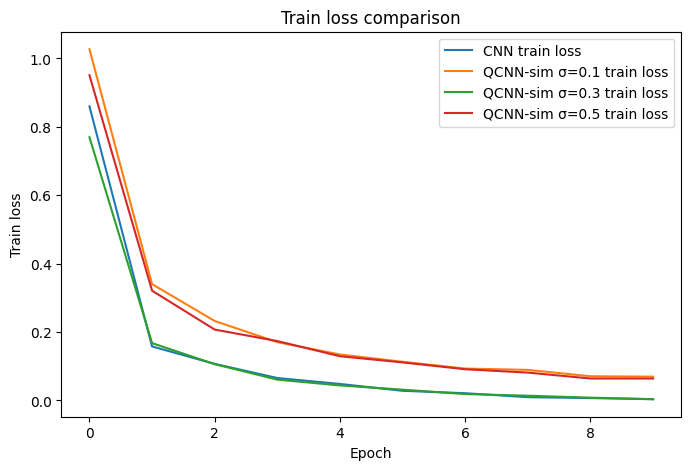

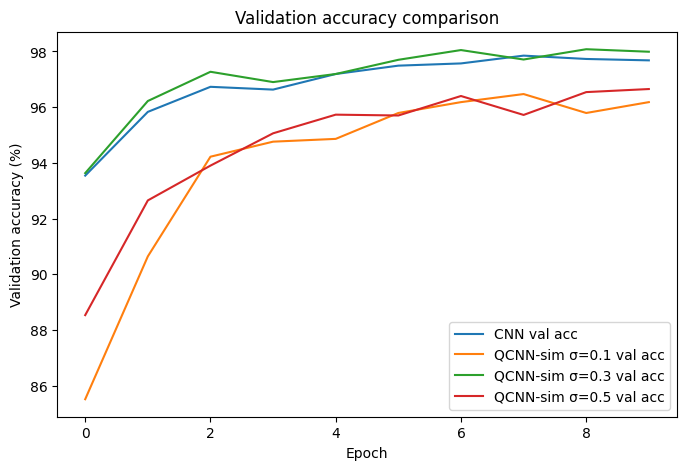

In [ ]:
# Plot loss and accuracy curves
plt.figure()
plt.plot(history_cnn['train_loss'], label='CNN train loss')
plt.plot(history_qcnn1['train_loss'], label='QCNN-sim σ=0.1 train loss')
plt.plot(history_qcnn2['train_loss'], label='QCNN-sim σ=0.3 train loss')
plt.plot(history_qcnn3['train_loss'], label='QCNN-sim σ=0.5 train loss')
plt.xlabel('Epoch'); plt.ylabel('Train loss'); plt.legend(); plt.title('Train loss comparison')
plt.show()

plt.figure()
plt.plot(history_cnn['val_acc'], label='CNN val acc')
plt.plot(history_qcnn1['val_acc'], label='QCNN-sim σ=0.1 val acc')
plt.plot(history_qcnn2['val_acc'], label='QCNN-sim σ=0.3 val acc')
plt.plot(history_qcnn3['val_acc'], label='QCNN-sim σ=0.5 val acc')
plt.xlabel('Epoch'); plt.ylabel('Validation accuracy (%)'); plt.legend(); plt.title('Validation accuracy comparison')
plt.show()

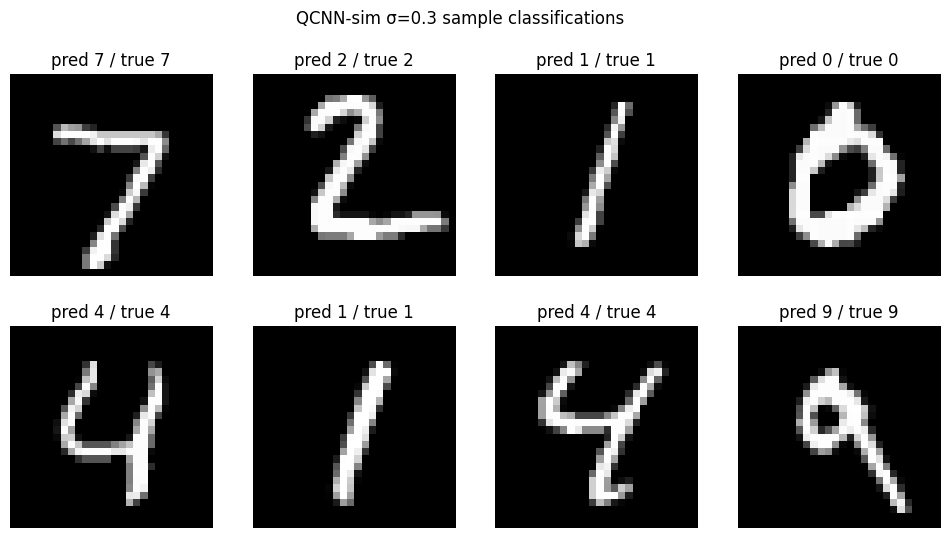

In [ ]:
# Show sample classifications from QCNN-sim
qcnn2.eval()
xb, yb = next(iter(val_loader))
xb, yb = xb.to(device), yb.to(device)
with torch.no_grad():
    out = qcnn2(xb)
    preds = out.argmax(dim=1)

# display 8 sample images with predicted/true labels
plt.figure(figsize=(12,6))
for i in range(8):
    plt.subplot(2,4,i+1)
    imshow(xb[i].cpu(), title=f'pred {preds[i].item()} / true {yb[i].item()}')
plt.suptitle('QCNN-sim σ=0.3 sample classifications')
plt.show()

## Visualising the Quantum Circuit

We include a small **parameterised quantum circuit** with Qiskit, representing a QCNN layer.

- Each qubit corresponds to a region of the input (like a convolutional filter).  
- Parameterised rotations (e.g., $R_z(\theta), R_y(\phi)$) represent trainable weights.  
- Entangling gates (CNOTs) capture correlations between input regions.  

This provides a **visual and intuitive analogy**: convolutional filters in CNNs ↔ parameterised gates in QCNNs.


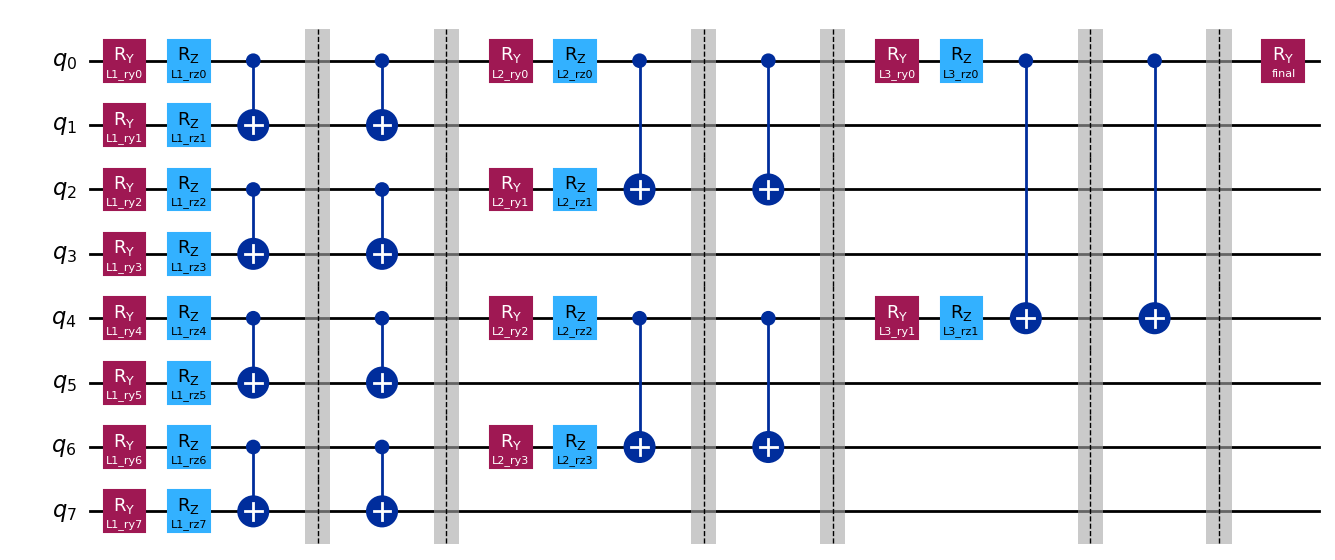

In [ ]:
from qiskit import QuantumCircuit
from qiskit.circuit import Parameter

def qcnn_layer(qc, qubits, prefix):
    """Apply convolution (rotations + entangling) on given qubits"""
    for i, q in enumerate(qubits):
        qc.ry(Parameter(f"{prefix}_ry{i}"), q)
        qc.rz(Parameter(f"{prefix}_rz{i}"), q)
    for i in range(0, len(qubits), 2):
        qc.cx(qubits[i], qubits[i+1])
    qc.barrier()

def qcnn_pool(qc, qubits):
    """Pooling: entangle neighbors, discard half"""
    new_qubits = []
    for i in range(0, len(qubits), 2):
        qc.cx(qubits[i], qubits[i+1])
        new_qubits.append(qubits[i])  # keep only first of each pair
    qc.barrier()
    return new_qubits

# Build QCNN circuit
qc = QuantumCircuit(8)

# Input layer
qcnn_layer(qc, list(range(8)), "L1")
# Pool 8 -> 4
qubits = qcnn_pool(qc, list(range(8)))

# Next layer
qcnn_layer(qc, qubits, "L2")
# Pool 4 -> 2
qubits = qcnn_pool(qc, qubits)

# Next layer
qcnn_layer(qc, qubits, "L3")
# Pool 2 -> 1
qubits = qcnn_pool(qc, qubits)

# Final rotation on single qubit
qc.ry(Parameter("final"), qubits[0])

qc.draw("mpl")



## References

[1] PennyLane, “Glossary: QCNN,” PennyLane. [Online]. Available: https://pennylane.ai/qml/glossary/qcnn.

[2] I. Cong, S. Choi, and M. D. Lukin, “Quantum Convolutional Neural Networks,” Nature Physics (2019) [Online]. Available: https://arxiv.org/abs/1810.03787.

[3] I. Kerenidis, J. Landman, and A. Prakash, “Quantum Algorithms for Deep Convolutional Neural Networks,” in International Conference on Learning Representations 2020. [Online]. Available: https://arxiv.org/abs/1911.01117.

## AI Acknowledgment
This code was developed with the assistance of **ChatGPT (OpenAI)** and **Gemini (Google DeepMind)**. These tools were used to support code generation, debugging, and documentation, ensuring clarity and efficiency in implementation.

